In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad
from jax import random
from functools import partial
from jax.nn import relu, softplus

import matplotlib.pyplot as plt
import scipy.io
from scipy.interpolate import griddata

import time
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import mpmath

from Pwp_class import PiecewiseLinearPolynomials
from minmax_opt_class import pytree_l2_norm, MinMaxOptProb
from NN_class import MLP

# Generate key which is used to generate random numbers
key = random.PRNGKey(1)
 

In [45]:
# # exact solution
# nu = 4.84*10**-4
# c = 0.3
# ka = 1/2*np.sqrt(c/nu)
# om = c*ka
# x0 = 6
# def exact_sol(x, t):
#     return 3*c/np.cosh(ka*x-om*t-x0)**2
nu = 0.001

# def u0(x):
#     return -0.5*(jnp.sign(x) - 1)
# def u_exact(t, x):
#     return u0(x-0.5*t)

# def u0(x):
#     return -jnp.sign(x)
# def u_exact(t, x):
#     return u0(x)


def u_exact(t, x):
    # Initialize u as zero
    u = 0.0
    # Condition 1: x < 0, u = 0 (already zero by default)
    # Condition 2: 0 < x < t and t > 0, u = x/t
    u = jnp.where((x > 0) & (x < t) & (t > 0), x / t, u)
    
    # Condition 3: t < x < 1 + t/2, u = 1
    u = jnp.where((x > t) & (x < 1 + t / 2), 1.0, u)
    
    # Condition 4: x > 1 + t/2, u = 0 (already zero by default)
    return u
vmap_u_exact = vmap(u_exact, in_axes=(0, 0), out_axes=0)

def u0(x):
    u = jnp.zeros_like(x)
    u = jnp.where((x > 0) & (x < 1), 1.0, u)
    return u

# Boundary at x=-1
def u1(x):
    u = jnp.zeros_like(x)
    return u

# Boundary at x=1
def u2(x):
    u = jnp.zeros_like(x)
    return u

def res_visc(u_quad, u_t, u_x, u_xx, nu):
    return u_t + u_quad * u_x - nu*u_xx
def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x


t_min = 0
t_max = 1
x_min = -1
x_max = 2
Nt = 101
Nx = 301

t = np.linspace(t_min, t_max, num = Nt)
x = np.linspace(x_min, x_max, num = Nx)
X, T = np.meshgrid(x, t)
layers_out = [2, 50, 50, 50, 50, 1]

Exact = vmap_u_exact(T, X)


# data = scipy.io.loadmat('/content/drive/My Drive/Colab Notebooks/KDV_IntConstra.mat');

# t = data['t'].flatten()[:,None]
# x = data['x'].flatten()[:,None]
# Exact = np.real(data['usol']).T

# t_size = len(t)
# X, T = np.meshgrid(x,t)

X_star = np.hstack((T.flatten()[:,None], X.flatten()[:,None]))
u_star = Exact.flatten()[:,None]

# Domain bounds
lb = X_star.min(0)
ub = X_star.max(0)

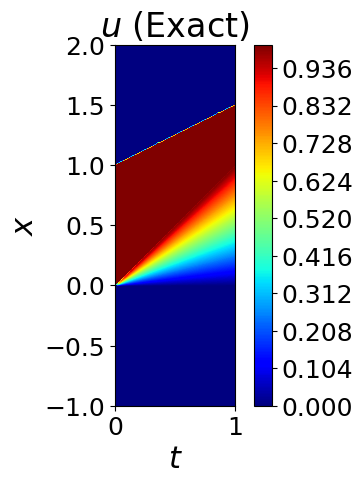

In [46]:
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, np.squeeze(Exact), 300, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (Exact)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConstEx')

In [47]:
def initialize_NN(layers, key):
    params = []
    num_layers = len(layers)
    keys = random.split(key, len(layers))
    a = jnp.sqrt(0.01)
    params.append(a)
    for l in range(0, num_layers-1):
        W = xavier_init((layers[l], layers[l+1]), keys[l])
        b = jnp.zeros((layers[l+1],), dtype=np.float32)
        params.append((W,b))
    return params

def xavier_init(size, key):
    in_dim = size[0]
    out_dim = size[1]
    xavier_stddev = jnp.sqrt(2/(in_dim + out_dim))
    return random.truncated_normal(key, -2, 2, shape=(out_dim, in_dim), dtype=np.float32)*xavier_stddev

def net_u(params, t, x):
    t = t.reshape((t.size,))
    x = x.reshape((x.size,))
    X = jnp.concatenate([t,x])
    X = 2.0*(X - lb)/(ub - lb) - 1.0
    num_layers = len(params)
    a = params[0]
    for l in range(1, num_layers-1):
        W, b = params[l]
        X = jnp.tanh(10.0*a*jnp.dot(W, X) + b)
        # X = relu(10.0*a*jnp.dot(W, X) + b)
        # X = softplus(10.0*a*jnp.dot(W, X) + b)
    W, b = params_out[-1]
    Y = jnp.dot(W,X) + b
    Y = jnp.squeeze(Y)
    return Y

vmap_net_u = jit(vmap(net_u, in_axes=(None, 0, 0), out_axes=0))
net_u_t = jit(vmap(grad(net_u, 1), in_axes = (None, 0, 0), out_axes=0))
net_u_x = jit(vmap(grad(net_u, 2), in_axes = (None, 0, 0), out_axes=0))
net_u_xx = jit(vmap(grad(grad(net_u, 2),2), in_axes = (None, 0, 0), out_axes=0))
net_u_xxx = jit(vmap(grad(grad(grad(net_u, 2), 2), 2), in_axes = (None, 0, 0), out_axes=0))

def net_f(params_out, t, x, nu):
    u = vmap_net_u(params_out, t, x)
    u_t = net_u_t(params_out, t, x)
    u_x = net_u_x(params_out, t, x)
    u_xx = net_u_xx(params_out, t, x)
    u_xxx = net_u_xxx(params_out, t, x)
    f = u_t + u*u_x - nu*u_xx
    return f

def lhs(d, N):
    return np.random.rand(N,d)

In [48]:
xx1 = np.hstack((T[0:1,:].T, X[0:1,:].T)) # (N_x,2) matrix, the initial condition points. Note t comes before x
# uu1 = Exact[0:1,:].T # (N_x, 1) matrix, the initial value
uu1 = u0(X[0:1,:].T)
xx2 = np.hstack((T[:,0:1], X[:,0:1])) # (N_t,2) matrix, the left bounary points
uu2 = u1(X[:,0:1]) # (N_t,1) matrix, the left bounary values
xx3 = np.hstack((T[:,-1:], X[:,-1:])) # (N_t,2) matrix, the right bounary points
uu3 = u2(X[:,-1:]) # (N_t,1) matrix, the right bounary values

# X_bc is the boundary and initial data sample, with u_bc as the function value
# X_f_train is the random points + X_bc

X_bc = np.vstack([xx1, xx2, xx3])
u_bc = np.vstack([uu1, uu2, uu3])
# X_f_train = lb + (ub-lb)*lhs(2, N_f)
# X_f_train = np.vstack((X_f_train, X_bc))
optProb = MinMaxOptProb(
    N_t=16,
    N_x=48,
    lr_theta=0.001,
    N_bc=Nt,
    N_ic=Nx,
    t_min=t_min, t_max=t_max, x_min=x_min, x_max=x_max,
    hidden_dims=(64, 64, 64, 64),
    seed=0,
    u0=u0, u1=u1, u2=u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,
)
quad_points = optProb.pwp.quad_points
quad_weights = optProb.pwp.quad_weights
X_f_train = quad_points


# # make the order of X_bc and u_bc to be random
# idx = np.random.choice(X_bc.shape[0], N_u, replace=False)
# X_bc = X_bc[idx, :]
# u_bc = u_bc[idx, :]
#u_bc = u_bc.reshape((u_bc.size,))

params_out = initialize_NN(layers_out, key)
# params_int = initialize_NN_extra(layers_int, key)
opt_init, opt_update, get_params = optimizers.adam(step_size=0.0005)
opt_state_out = opt_init(params_out)

In [49]:
def loss(params_out, X_train, nu, u_bc, X_bc, X_grid, X):
    u_pred_bc = vmap_net_u(params_out, X_bc[:,0], X_bc[:,1])
    res = net_f(params_out, X_train[:,0], X_train[:,1], nu)
    loss_int = jnp.dot(res**2, quad_weights)
    l = 50*jnp.mean(jnp.square(u_pred_bc-u_bc)) + loss_int
    return l

In [50]:
import time

@jit
def step_out(i, opt_state_out, X_train, nu, u_bc, X_bc, X_grid, X):
    params_out = get_params(opt_state_out)
    val, g = value_and_grad(loss)(params_out, X_train, nu, u_bc, X_bc, X_grid, X)
    return val, opt_update(i, g, opt_state_out)

start_time = time.perf_counter()
loss_val_his = []
# inv_val_his = []
for i in range(10001):
    loss_val, opt_state_out = step_out(i, opt_state_out, X_f_train, nu, u_bc[:,0], X_bc, X_star, X)
    # inv_val = get_invariants(params_out, params_int, nu, X_star, X)
    # loss_val = loss(params_out, X_f_train, nu, u_bc[:,0], X_bc, X_star, X)
    loss_val_his.append(loss_val)
    # inv_val_his.append(inv_val)
    if i % 200 == 0:
        #elapsed = time.time() - start_time
        # params_out = get_params(opt_state_out)
        # a_value = params_out[0]
        print('It: %d, Loss: %.3e' % (i, loss_val))
params_out = get_params(opt_state_out)
loss_val_his = jnp.array(loss_val_his)
# inv_val_his = jnp.array(inv_val_his)
end_time = time.perf_counter()
train_total_time = (end_time - start_time)
print(f"Train total time: {train_total_time:.8f} seconds")

It: 0, Loss: 8.511e+00
It: 200, Loss: 1.238e+00
It: 400, Loss: 6.654e-01
It: 600, Loss: 3.981e-01
It: 800, Loss: 3.018e-01
It: 1000, Loss: 2.447e-01
It: 1200, Loss: 1.928e-01
It: 1400, Loss: 1.237e-01
It: 1600, Loss: 1.727e-01
It: 1800, Loss: 9.388e-02
It: 2000, Loss: 1.074e-01
It: 2200, Loss: 3.595e-02
It: 2400, Loss: 6.161e-01
It: 2600, Loss: 3.075e-01
It: 2800, Loss: 2.493e-01
It: 3000, Loss: 2.186e-01
It: 3200, Loss: 2.015e-01
It: 3400, Loss: 1.858e-01
It: 3600, Loss: 1.717e-01
It: 3800, Loss: 1.596e-01
It: 4000, Loss: 2.148e-01
It: 4200, Loss: 1.729e-01
It: 4400, Loss: 1.412e-01
It: 4600, Loss: 1.076e-01
It: 4800, Loss: 7.634e-02
It: 5000, Loss: 9.095e-02
It: 5200, Loss: 4.311e-02
It: 5400, Loss: 3.628e-02
It: 5600, Loss: 3.232e-02
It: 5800, Loss: 2.680e-02
It: 6000, Loss: 2.308e-02
It: 6200, Loss: 1.843e-02
It: 6400, Loss: 3.896e-01
It: 6600, Loss: 2.492e-01
It: 6800, Loss: 2.040e-01
It: 7000, Loss: 1.681e-01
It: 7200, Loss: 2.620e-01
It: 7400, Loss: 2.153e-01
It: 7600, Loss: 1.8

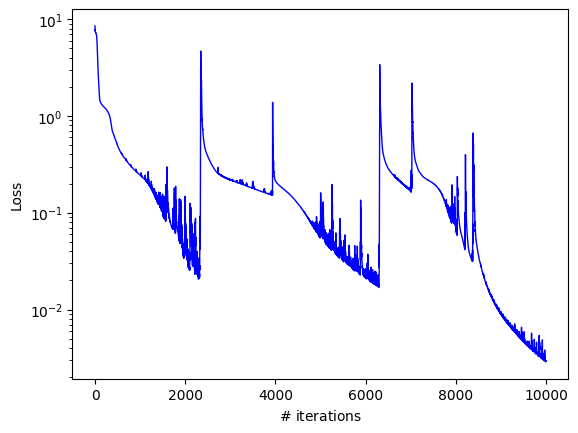

<Figure size 640x480 with 0 Axes>

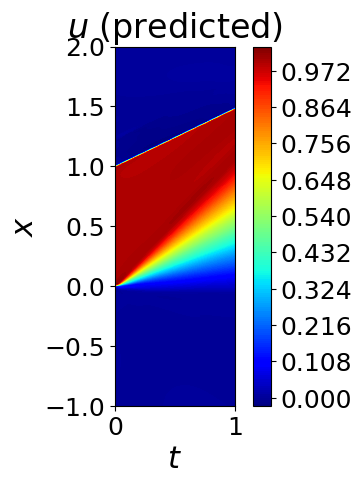

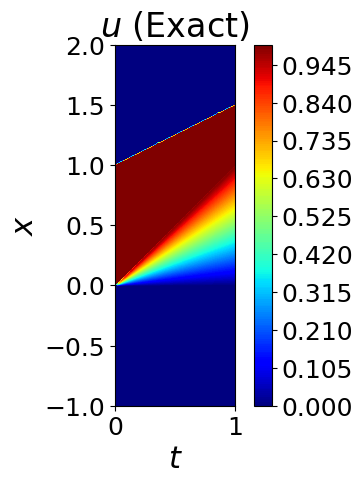

In [52]:
u_pred = vmap_net_u(params_out, X_star[:,0], X_star[:,1])
U_pred = griddata(X_star, u_pred.flatten(), (T, X), method='cubic')

plt.plot(loss_val_his,  'b-', linewidth = 1)
plt.xlabel('$\#$ iterations')
plt.ylabel('Loss')
plt.yscale('log')

fig = plt.figure()
# plt.plot(inv_val_his,  'b-', linewidth = 1)
# plt.xlabel('$\#$ iterations')
# plt.ylabel('Invariants_sum')
# plt.yscale('log')

#ax.legend(frameon=False, loc = 'best')
#ax.set_title('$u(x,y)$', fontsize = 10)
#ax.axis('square')
#savefig('./figures/KdV_IC_MSEhistory')

#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, U_pred, 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
#    ax.set_xlim(0, 1)
#    ax.set_ylim(0, 2)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (predicted)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)
#plt.plot(xx1[:,0:1],xx1[:,1:2], 'kx',markersize=15)
#plt.plot(xx2[:,0:1],xx2[:,1:2], 'rx',markersize=15)
#plt.plot(xx3[:,0:1],xx3[:,1:2], 'gx',markersize=15)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConst')
#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, np.squeeze(Exact), 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
# ax.set_xlim(0, 1)
# ax.set_ylim(-1, 1)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (Exact)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConstEx')

In [13]:
X_bc[]

array([[ 0.  , -1.  ],
       [ 0.  , -0.99],
       [ 0.  , -0.98],
       ...,
       [ 0.98,  2.  ],
       [ 0.99,  2.  ],
       [ 1.  ,  2.  ]])

In [24]:
@jit
def step_out(i, opt_state_out, X_train, nu, u_bc, X_bc, X_grid, X):
    params_out = get_params(opt_state_out)
    val, g = value_and_grad(loss)(params_out, X_train, nu, u_bc, X_bc, X_grid, X)
    return val, opt_update(i, g, opt_state_out)

# @jit
# def step_int(i, opt_state_int, params_out, nu, X_grid, X):
#     params_int = get_params(opt_state_int)
#     val, g = value_and_grad(get_invariants, 1)(params_out, params_int, nu, X_grid, X)
#     return val, opt_update(i, g, opt_state_int)

opt_init, opt_update, get_params = optimizers.adam(step_size=0.0003)
opt_state_out = opt_init(params_out)
# opt_state_int = opt_init(params_int)


loss_val_his = []
# inv_val_his = []
for i in range(20001):
    loss_val, opt_state_out = step_out(i, opt_state_out, X_f_train, nu, u_bc[:,0], X_bc, X_star, X)
    # inv_val = get_invariants(params_out, params_int, nu, X_star, X)
    # loss_val = loss(params_out, X_f_train, nu, u_bc[:,0], X_bc, X_star, X)
    loss_val_his.append(loss_val)
    # inv_val_his.append(inv_val)
    if i % 200 == 0:
        #elapsed = time.time() - start_time
        # params_out = get_params(opt_state_out)
        # a_value = params_out[0]
        print('It: %d, Loss: %.3e' % (i, loss_val))
params_out = get_params(opt_state_out)
loss_val_his = jnp.array(loss_val_his)
# inv_val_his = jnp.array(inv_val_his)

It: 0, Loss: 2.880e+01
It: 200, Loss: 4.607e+00
It: 400, Loss: 1.956e+00
It: 600, Loss: 1.529e+00
It: 800, Loss: 1.261e+00
It: 1000, Loss: 9.182e-01
It: 1200, Loss: 3.606e-02
It: 1400, Loss: 4.901e-03
It: 1600, Loss: 3.905e-03
It: 1800, Loss: 3.191e-03
It: 2000, Loss: 2.943e-03
It: 2200, Loss: 2.768e-03
It: 2400, Loss: 2.613e-03
It: 2600, Loss: 2.481e-03
It: 2800, Loss: 2.321e-03
It: 3000, Loss: 2.177e-03
It: 3200, Loss: 2.194e-03
It: 3400, Loss: 2.815e-03
It: 3600, Loss: 1.847e-03
It: 3800, Loss: 2.409e-03
It: 4000, Loss: 1.676e-03
It: 4200, Loss: 1.664e-03
It: 4400, Loss: 1.622e-03
It: 4600, Loss: 1.578e-03
It: 4800, Loss: 2.458e-03
It: 5000, Loss: 1.936e-03
It: 5200, Loss: 1.347e-03
It: 5400, Loss: 1.375e-03
It: 5600, Loss: 1.436e-03
It: 5800, Loss: 1.570e-03
It: 6000, Loss: 2.891e-03
It: 6200, Loss: 1.327e-03
It: 6400, Loss: 1.276e-03
It: 6600, Loss: 1.326e-03
It: 6800, Loss: 1.360e-03
It: 7000, Loss: 1.563e-03
It: 7200, Loss: 4.939e-03
It: 7400, Loss: 9.301e-04
It: 7600, Loss: 9.6

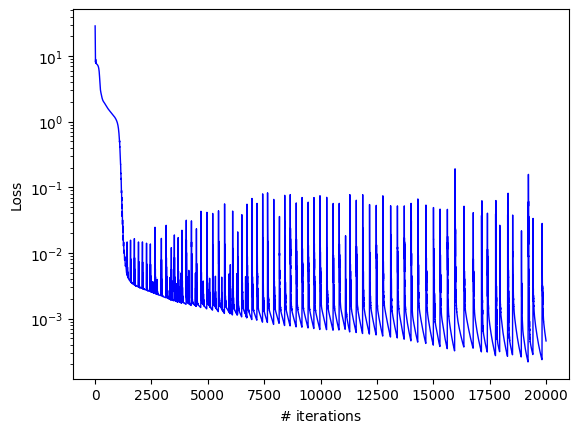

<Figure size 640x480 with 0 Axes>

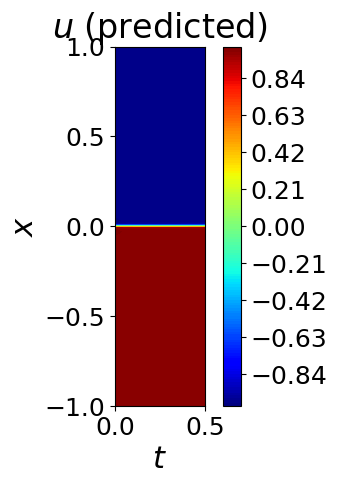

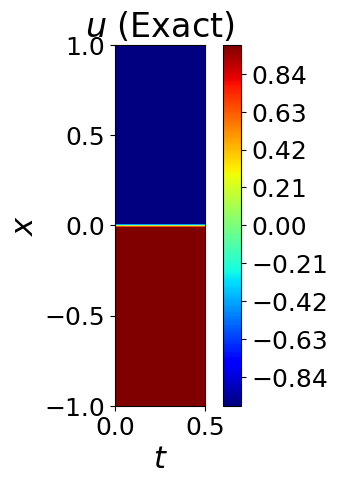

In [25]:
u_pred = vmap_net_u(params_out, X_star[:,0], X_star[:,1])
U_pred = griddata(X_star, u_pred.flatten(), (T, X), method='cubic')

plt.plot(loss_val_his,  'b-', linewidth = 1)
plt.xlabel('$\#$ iterations')
plt.ylabel('Loss')
plt.yscale('log')

fig = plt.figure()
# plt.plot(inv_val_his,  'b-', linewidth = 1)
# plt.xlabel('$\#$ iterations')
# plt.ylabel('Invariants_sum')
# plt.yscale('log')

#ax.legend(frameon=False, loc = 'best')
#ax.set_title('$u(x,y)$', fontsize = 10)
#ax.axis('square')
#savefig('./figures/KdV_IC_MSEhistory')

#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, U_pred, 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
#    ax.set_xlim(0, 1)
#    ax.set_ylim(0, 2)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (predicted)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)
#plt.plot(xx1[:,0:1],xx1[:,1:2], 'kx',markersize=15)
#plt.plot(xx2[:,0:1],xx2[:,1:2], 'rx',markersize=15)
#plt.plot(xx3[:,0:1],xx3[:,1:2], 'gx',markersize=15)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConst')
#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, np.squeeze(Exact), 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
# ax.set_xlim(0, 1)
# ax.set_ylim(-1, 1)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (Exact)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConstEx')

In [35]:
@jit
def step_out(i, opt_state_out, X_train, nu, u_bc, X_bc, X_grid, X):
    params_out = get_params(opt_state_out)
    val, g = value_and_grad(loss)(params_out, X_train, nu, u_bc, X_bc, X_grid, X)
    return val, opt_update(i, g, opt_state_out)

# @jit
# def step_int(i, opt_state_int, params_out, nu, X_grid, X):
#     params_int = get_params(opt_state_int)
#     val, g = value_and_grad(get_invariants, 1)(params_out, params_int, nu, X_grid, X)
#     return val, opt_update(i, g, opt_state_int)

opt_init, opt_update, get_params = optimizers.adam(step_size=0.0003)
opt_state_out = opt_init(params_out)
# opt_state_int = opt_init(params_int)


loss_val_his = []
# inv_val_his = []
for i in range(50001):
    loss_val, opt_state_out = step_out(i, opt_state_out, X_f_train, nu, u_bc[:,0], X_bc, X_star, X)
    # inv_val = get_invariants(params_out, params_int, nu, X_star, X)
    # loss_val = loss(params_out, X_f_train, nu, u_bc[:,0], X_bc, X_star, X)
    loss_val_his.append(loss_val)
    # inv_val_his.append(inv_val)
    if i % 200 == 0:
        #elapsed = time.time() - start_time
        # params_out = get_params(opt_state_out)
        # a_value = params_out[0]
        print('It: %d, Loss: %.3e' % (i, loss_val))
params_out = get_params(opt_state_out)
loss_val_his = jnp.array(loss_val_his)
# inv_val_his = jnp.array(inv_val_his)

It: 0, Loss: 1.135e+02
It: 200, Loss: 1.604e+00
It: 400, Loss: 1.360e+00
It: 600, Loss: 1.181e+00
It: 800, Loss: 9.686e-01
It: 1000, Loss: 6.331e-01
It: 1200, Loss: 2.330e-01
It: 1400, Loss: 8.722e-02
It: 1600, Loss: 3.482e-02
It: 1800, Loss: 2.185e-02
It: 2000, Loss: 1.588e-02
It: 2200, Loss: 1.340e-02
It: 2400, Loss: 1.196e-02
It: 2600, Loss: 8.598e-03
It: 2800, Loss: 8.533e-03
It: 3000, Loss: 9.727e-03
It: 3200, Loss: 9.360e-03
It: 3400, Loss: 1.029e-02
It: 3600, Loss: 6.267e-03
It: 3800, Loss: 5.398e-03
It: 4000, Loss: 5.712e-03
It: 4200, Loss: 1.379e-02
It: 4400, Loss: 3.791e-03
It: 4600, Loss: 3.967e-03
It: 4800, Loss: 6.631e-03
It: 5000, Loss: 3.923e-03
It: 5200, Loss: 1.140e-02
It: 5400, Loss: 4.440e-03
It: 5600, Loss: 3.012e-03
It: 5800, Loss: 1.053e-02
It: 6000, Loss: 3.137e-02
It: 6200, Loss: 2.788e-02
It: 6400, Loss: 9.941e-03
It: 6600, Loss: 4.950e-03
It: 6800, Loss: 4.152e-03
It: 7000, Loss: 3.780e-03
It: 7200, Loss: 5.180e-03
It: 7400, Loss: 3.355e-03
It: 7600, Loss: 3.3

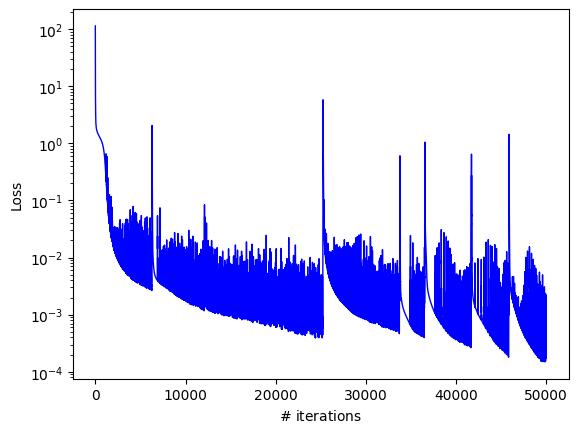

<Figure size 640x480 with 0 Axes>

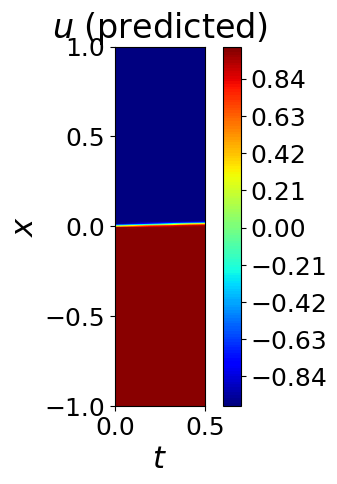

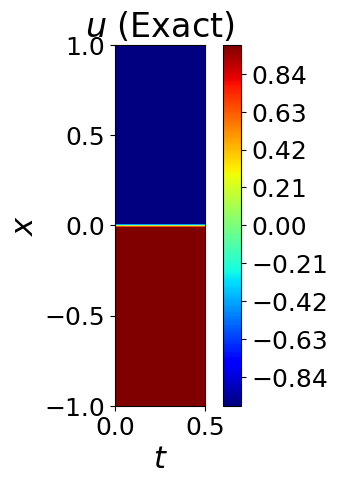

In [36]:
u_pred = vmap_net_u(params_out, X_star[:,0], X_star[:,1])
U_pred = griddata(X_star, u_pred.flatten(), (T, X), method='cubic')

plt.plot(loss_val_his,  'b-', linewidth = 1)
plt.xlabel('$\#$ iterations')
plt.ylabel('Loss')
plt.yscale('log')

fig = plt.figure()
# plt.plot(inv_val_his,  'b-', linewidth = 1)
# plt.xlabel('$\#$ iterations')
# plt.ylabel('Invariants_sum')
# plt.yscale('log')

#ax.legend(frameon=False, loc = 'best')
#ax.set_title('$u(x,y)$', fontsize = 10)
#ax.axis('square')
#savefig('./figures/KdV_IC_MSEhistory')

#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, U_pred, 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
#    ax.set_xlim(0, 1)
#    ax.set_ylim(0, 2)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (predicted)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)
#plt.plot(xx1[:,0:1],xx1[:,1:2], 'kx',markersize=15)
#plt.plot(xx2[:,0:1],xx2[:,1:2], 'rx',markersize=15)
#plt.plot(xx3[:,0:1],xx3[:,1:2], 'gx',markersize=15)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConst')
#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, np.squeeze(Exact), 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
# ax.set_xlim(0, 1)
# ax.set_ylim(-1, 1)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (Exact)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConstEx')

In [7]:
@jit
def step_out(i, opt_state_out, X_train, nu, u_bc, X_bc, X_grid, X):
    params_out = get_params(opt_state_out)
    val, g = value_and_grad(loss)(params_out, X_train, nu, u_bc, X_bc, X_grid, X)
    return val, opt_update(i, g, opt_state_out)

# @jit
# def step_int(i, opt_state_int, params_out, nu, X_grid, X):
#     params_int = get_params(opt_state_int)
#     val, g = value_and_grad(get_invariants, 1)(params_out, params_int, nu, X_grid, X)
#     return val, opt_update(i, g, opt_state_int)

opt_init, opt_update, get_params = optimizers.adam(step_size=0.0002)
opt_state_out = opt_init(params_out)
# opt_state_int = opt_init(params_int)


loss_val_his = []
# inv_val_his = []
for i in range(50001):
    loss_val, opt_state_out = step_out(i, opt_state_out, X_f_train, nu, u_bc[:,0], X_bc, X_star, X)
    # inv_val = get_invariants(params_out, params_int, nu, X_star, X)
    # loss_val = loss(params_out, X_f_train, nu, u_bc[:,0], X_bc, X_star, X)
    loss_val_his.append(loss_val)
    # inv_val_his.append(inv_val)
    if i % 200 == 0:
        #elapsed = time.time() - start_time
        # params_out = get_params(opt_state_out)
        # a_value = params_out[0]
        print('It: %d, Loss: %.3e' % (i, loss_val))
params_out = get_params(opt_state_out)
loss_val_his = jnp.array(loss_val_his)
# inv_val_his = jnp.array(inv_val_his)

It: 0, Loss: 1.513e+02
It: 200, Loss: 6.319e-01
It: 400, Loss: 4.081e-01
It: 600, Loss: 3.422e-01
It: 800, Loss: 3.058e-01
It: 1000, Loss: 2.806e-01
It: 1200, Loss: 2.612e-01
It: 1400, Loss: 2.459e-01
It: 1600, Loss: 2.340e-01
It: 1800, Loss: 2.243e-01
It: 2000, Loss: 2.159e-01
It: 2200, Loss: 2.083e-01
It: 2400, Loss: 2.013e-01
It: 2600, Loss: 1.945e-01
It: 2800, Loss: 1.879e-01
It: 3000, Loss: 1.822e-01
It: 3200, Loss: 1.749e-01
It: 3400, Loss: 1.686e-01
It: 3600, Loss: 1.621e-01
It: 3800, Loss: 1.576e-01
It: 4000, Loss: 1.491e-01
It: 4200, Loss: 1.418e-01
It: 4400, Loss: 1.348e-01
It: 4600, Loss: 1.271e-01
It: 4800, Loss: 1.179e-01
It: 5000, Loss: 1.062e-01
It: 5200, Loss: 9.151e-02
It: 5400, Loss: 7.258e-02
It: 5600, Loss: 5.489e-02
It: 5800, Loss: 4.388e-02
It: 6000, Loss: 3.215e-02
It: 6200, Loss: 2.527e-02
It: 6400, Loss: 2.097e-02
It: 6600, Loss: 1.769e-02
It: 6800, Loss: 1.254e-02
It: 7000, Loss: 9.932e-03
It: 7200, Loss: 1.121e-02
It: 7400, Loss: 7.762e-03
It: 7600, Loss: 5.2

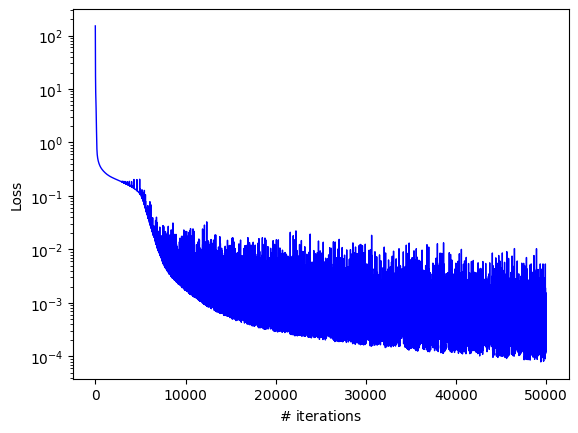

<Figure size 640x480 with 0 Axes>

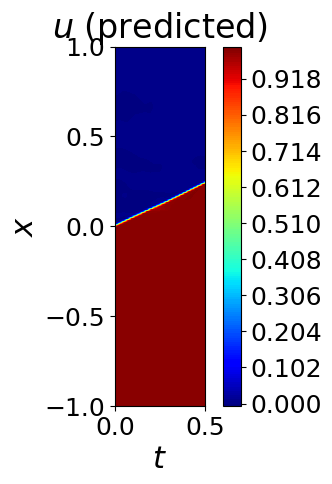

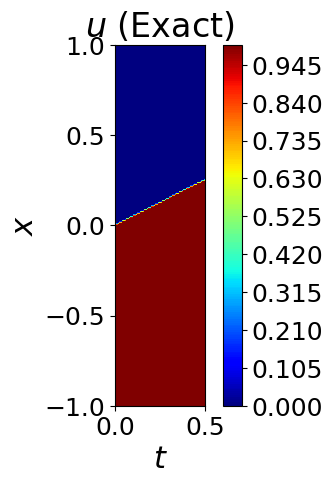

In [9]:
u_pred = vmap_net_u(params_out, X_star[:,0], X_star[:,1])
U_pred = griddata(X_star, u_pred.flatten(), (T, X), method='cubic')

plt.plot(loss_val_his,  'b-', linewidth = 1)
plt.xlabel('$\#$ iterations')
plt.ylabel('Loss')
plt.yscale('log')

fig = plt.figure()
# plt.plot(inv_val_his,  'b-', linewidth = 1)
# plt.xlabel('$\#$ iterations')
# plt.ylabel('Invariants_sum')
# plt.yscale('log')

#ax.legend(frameon=False, loc = 'best')
#ax.set_title('$u(x,y)$', fontsize = 10)
#ax.axis('square')
#savefig('./figures/KdV_IC_MSEhistory')

#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, U_pred, 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
#    ax.set_xlim(0, 1)
#    ax.set_ylim(0, 2)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (predicted)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)
#plt.plot(xx1[:,0:1],xx1[:,1:2], 'kx',markersize=15)
#plt.plot(xx2[:,0:1],xx2[:,1:2], 'rx',markersize=15)
#plt.plot(xx3[:,0:1],xx3[:,1:2], 'gx',markersize=15)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConst')
#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, np.squeeze(Exact), 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
# ax.set_xlim(0, 1)
# ax.set_ylim(-1, 1)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (Exact)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConstEx')

In [15]:
optProb = MinMaxOptProb(
    N_t=16,
    N_x=32,
    lr_theta=0.01,
    N_bc=100,
    N_ic=400,
    t_min=0, t_max=0.5, x_min=-1, x_max=1,
    hidden_dims=(64, 64, 64, 64),
    seed=0,
    u0=u0, u1=u1, u2=u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,
)
quad_points = optProb.pwp.quad_points
quad_weights = optProb.pwp.quad_weights

In [16]:
np.max(quad_points[:,0])

Array(0.5, dtype=float32)

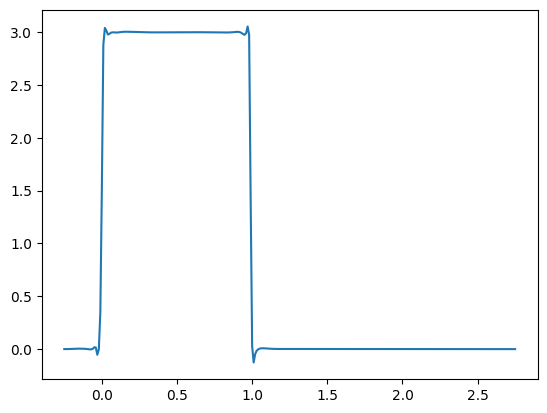

In [17]:
plt.plot(x, U_pred[0,:])

In [37]:
U_pred.shape

(101, 201)